# (U,W) Mixture Graphs

A **(U,W) mixture** graph combines two very different regimes in one graph:

- a **dense** part, sampled from an ordinary graphon $W$ (every pair of nodes connects with some probability -- gives a dense, graphon-like "core"),
- a **sparse, hub-heavy** part, built from a mass partition (equivalently, a "line graphon" $U$: a block-diagonal matrix of disjoint cliques) -- this generates a handful of star graphs, i.e. a few very high-degree **hub** nodes each surrounded by many degree-1 leaves. It uses the inverse line graph or the root graph to generate stars from disjoint cliques. 

The two parts are then joined (either as a plain disjoint union, or with some random edges added between them). Depending on the $U$ and $W$ chosen, the result resembles real-world networks: a dense, well-mixed core plus a few outsized hubs sticking out of it.

This notebook:
1. generates a couple of example (U,W) mixtures,
2. estimates the mass partition $U$ (i.e. the hub structure) from a *given* graph,
3. uses that estimate to **predict the hub degrees of a future, larger graph** from the same process.

All functions come from `Graphon_Mixtures_Graphettes.py`, in the src folder.

In [ ]:
import sys

# On Colab: install igraph and download Graphon_Mixtures_Graphettes.py. Locally: read it from ../src.
if "google.colab" in sys.modules:
    !pip install -q python-igraph
    BASE = "https://raw.githubusercontent.com/sevvandi/sevvandi.github.io/BRANCH/assets/notebooks/NeurIPS_2026/src"
    !wget -q {BASE}/Graphon_Mixtures_Graphettes.py
else:
    sys.path.insert(0, "../src")

import numpy as np
import matplotlib.pyplot as plt
import igraph as ig


from Graphon_Mixtures_Graphettes import (
    sample_mixed_graph,
    generate_star_union,
    sample_graphon,
    line_graphon,
    plot_graphon,
    ring_graphon,
    sbm_graphon,
    extract_sparse,
    predict_hubs,
    plot_extract_sparse,
)

%matplotlib inline
rng = np.random.default_rng(0)

In [ ]:
import importlib
import Graphon_Mixtures_Graphettes

from Graphon_Mixtures_Graphettes import (
    sample_mixed_graph,
    generate_star_union,
    sample_graphon,
    line_graphon,
    plot_graphon,
    ring_graphon,
    sbm_graphon,
    extract_sparse,
    predict_hubs,
    plot_extract_sparse,
)

## 1. Generating (U,W) mixtures

Two examples with different dense cores and different hub structures.

In [44]:
# --- Example A: uniform (Erdos-Renyi-like) dense core + 3 hubs ---
W_A = np.full((150, 150), 0.02)  # very sparse core, so hubs stand out clearly
wts_A = np.array([0.5, 0.3, 0.2])          # 3 hubs, sizes proportional to these
gr_A = sample_mixed_graph(W_A, wts_A, nd=150, ns=250, p=0.1, option=2, rng=rng)

print(f"Mixture A: {gr_A.vcount()} nodes, {gr_A.ecount()} edges")
print("Top degrees:", sorted(gr_A.degree(), reverse=True)[:6])

Mixture A: 400 nodes, 476 edges
Top degrees: [124, 74, 49, 9, 7, 7]


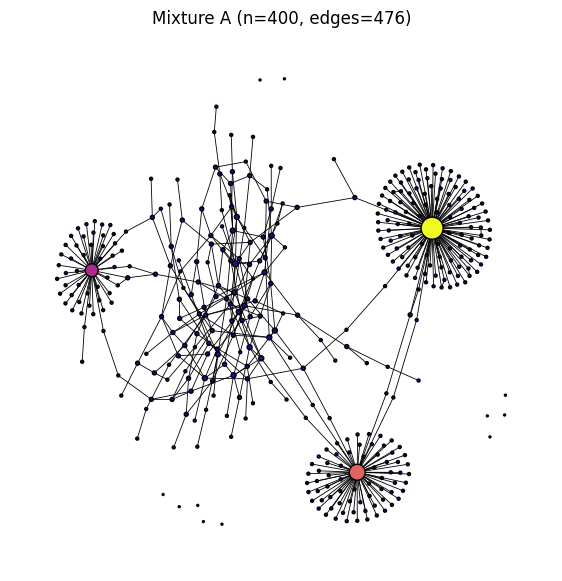

In [45]:
deg = np.array(gr_A.degree())
sizes = 2 + 20 * (deg / deg.max()) ** 0.6
cmap = plt.get_cmap("plasma")
colors = [cmap(d) for d in deg / deg.max()]

fig, ax = plt.subplots(figsize=(7, 7))
layout = gr_A.layout("fr")
ig.plot(gr_A, target=ax, layout=layout, vertex_size=sizes, vertex_color=colors,
        edge_color=(0.6, 0.6, 0.6, 0.5), edge_width=0.6)
ax.set_title(f"Mixture A (n={gr_A.vcount()}, edges={gr_A.ecount()})")
plt.show()

In [47]:
# --- Example B: 2-block SBM dense core + 5 (smaller) hubs ---
W_B = sbm_graphon(np.array([[0.15, 0.02], [0.02, 0.15]]), 100)
wts_B = np.array([0.35, 0.25, 0.2, 0.12, 0.08])   # 5 hubs
gr_B = sample_mixed_graph(W_B, wts_B, nd=200, ns=250, p=0.2, option=2, rng=rng)

print(f"Mixture B: {gr_B.vcount()} nodes, {gr_B.ecount()} edges")
print("Top degrees:", sorted(gr_B.degree(), reverse=True)[:6])

Mixture B: 451 nodes, 2209 edges
Top degrees: [88, 64, 50, 31, 31, 30]


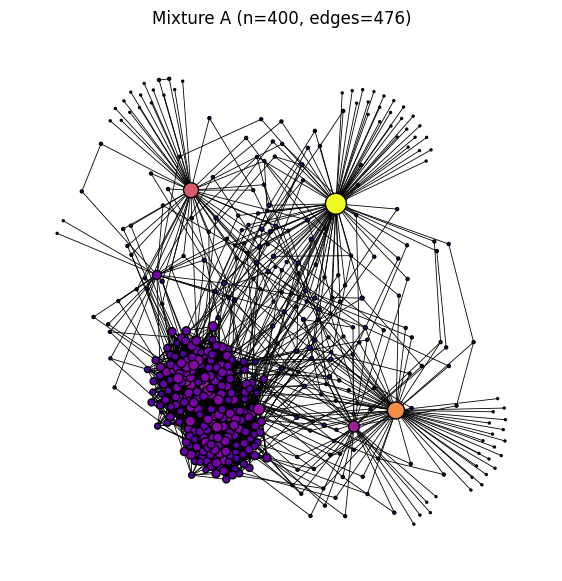

In [49]:
deg = np.array(gr_B.degree())
sizes = 1 + 20 * (deg / deg.max()) ** 0.6
cmap = plt.get_cmap("plasma")
colors = [cmap(d) for d in deg / deg.max()]

fig, ax = plt.subplots(figsize=(7, 7))
layout = gr_B.layout("fr")
ig.plot(gr_B, target=ax, layout=layout, vertex_size=sizes, vertex_color=colors,
        edge_color=(0.6, 0.6, 0.6, 0.5), edge_width=0.6)
ax.set_title(f"Mixture A (n={gr_A.vcount()}, edges={gr_A.ecount()})")
plt.show()

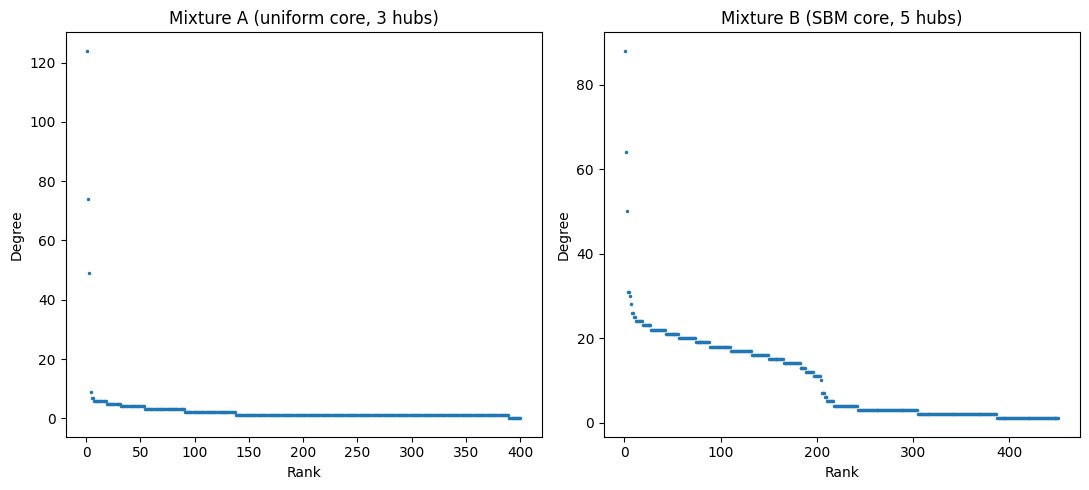

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, gr, title in zip(axes, [gr_A, gr_B], ["Mixture A (uniform core, 3 hubs)", "Mixture B (SBM core, 5 hubs)"]):
    deg = np.array(gr.degree())
    deg_sorted = np.sort(deg)[::-1]
    ax.plot(np.arange(1, len(deg_sorted) + 1), deg_sorted, ".", markersize=3)
    ax.set_xlabel("Rank")
    ax.set_ylabel("Degree")
    ax.set_title(title)
plt.tight_layout()
plt.show()

Both degree sequences show the signature (U,W)-mixture shape: a short run of very high-degree hub nodes, then a long, low, roughly flat tail from the dense core.

## 2. Estimating $U$ from a given graph

Given only the graph (not knowing the generating $W$ or `wts`), we can:
1. use `extract_sparse` to find where the "hub" regime ends and the "bulk" regime begins (a two-segment fit to the sorted, unique, logged degree sequence -- the breakpoint is the estimated number of hubs $\hat k$),
2. take the top $\hat k$ degrees and renormalize them into an estimated mass partition $\hat U$ (i.e. estimated `wts`),
3. compare the resulting line graphon $\hat U$ to the true one used to generate the graph.



Estimated number of hubs (cutoff): 3   (true number of hub *centers*: 3)


/Users/kan092/Library/CloudStorage/OneDrive-CSIRO/Documents/repos/NeurIPSEducation/notebooks/../src/Graphon_Mixtures_Graphettes.py:682: RankWarning: Polyfit may be poorly conditioned
  c2 = np.polyfit(x2, y2, 1)


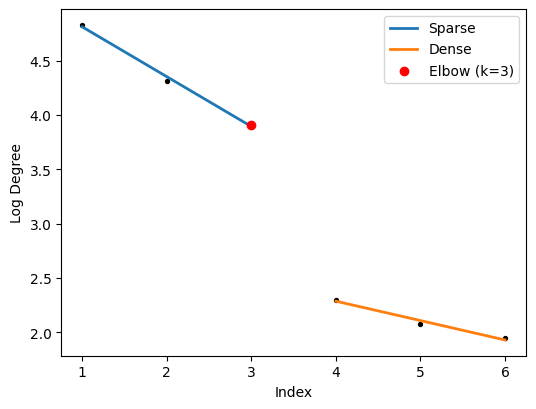

In [57]:
result_A = extract_sparse(gr_A)
print(f"Estimated number of hubs (cutoff): {result_A['num_hubs']}   (true number of hub *centers*: {len(wts_A)})")

fig, ax = plt.subplots(figsize=(6, 4.5))
plot_extract_sparse(result_A, ax=ax)
plt.show()

True wts:      [0.5 0.3 0.2]
Estimated wts: [0.502 0.3   0.198]


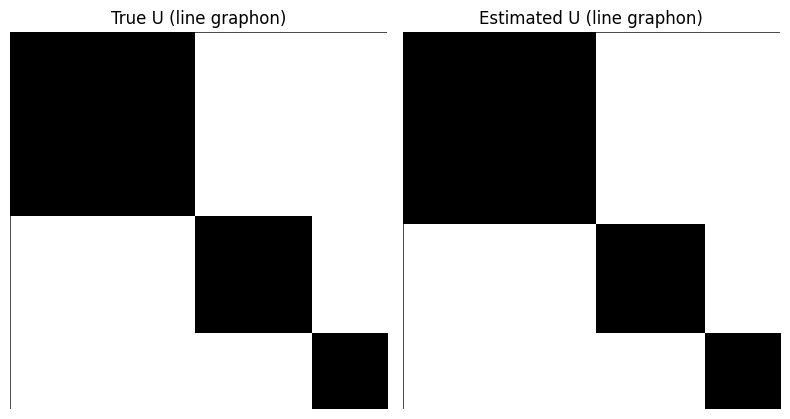

In [58]:
k_hat = result_A["num_hubs"]
top_degs = np.array(sorted(gr_A.degree(), reverse=True)[:k_hat])
wts_A_hat = top_degs / top_degs.sum()

print("True wts:     ", np.round(wts_A, 3))
print("Estimated wts:", np.round(wts_A_hat, 3))

U_true = line_graphon(wts_A)
U_hat = line_graphon(wts_A_hat)

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5))
plot_graphon(U_true, ax=axes[0])
axes[0].set_title("True U (line graphon)")
plot_graphon(U_hat, ax=axes[1])
axes[1].set_title("Estimated U (line graphon)")
plt.tight_layout()
plt.show()

The three true hubs (degrees 199, 119, 79) dominate the estimated mass partition, as expected.

## 3. Predicting the degrees of a future graph

Now suppose we've only ever seen `gr_A` (say, at $n=400$ nodes), and we want to predict what the hub degrees will look like in a **much larger** graph from the same process -- e.g. at $n=3000$. `predict_hubs` does this by linearly rescaling the current hub degrees by the ratio of node counts.

We'll check the prediction by actually sampling a bigger mixture graph (same $W$, same `wts`, larger `nd`/`ns`) and comparing.

In [66]:
n_future = 3000
k_hat = result_A["num_hubs"]  # reuse the hub count estimated above
predicted_degs = predict_hubs(gr_A, n=n_future, k=k_hat)
print("Predicted hub degrees at n=3000:", predicted_degs)

# Ground truth: actually sample a bigger graph from the same (W, wts), scaled up ~5x
scale = n_future / gr_A.vcount()
gr_A_future = sample_mixed_graph(
    W_A, wts_A, nd=int(150 * scale), ns=int(250 * scale), p=0.1, option=2, rng=rng
)
actual_degs = np.array(sorted(gr_A_future.degree(), reverse=True)[: len(predicted_degs)])

print("Actual hub degrees at n=%d:  " % gr_A_future.vcount(), actual_degs)

Predicted hub degrees at n=3000: [930 555 368]
Actual hub degrees at n=3001:   [939 563 376]


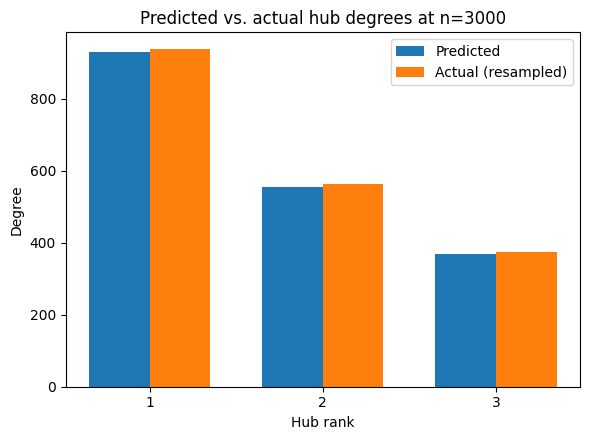

In [64]:
fig, ax = plt.subplots(figsize=(6, 4.5))
idx = np.arange(1, len(predicted_degs) + 1)
width = 0.35
ax.bar(idx - width / 2, predicted_degs, width, label="Predicted", color="tab:blue")
ax.bar(idx + width / 2, actual_degs, width, label="Actual (resampled)", color="tab:orange")
ax.set_xlabel("Hub rank")
ax.set_ylabel("Degree")
ax.set_xticks(idx)
ax.legend()
ax.set_title(f"Predicted vs. actual hub degrees at n={n_future}")
plt.tight_layout()
plt.show()

## Recap

- `sample_mixed_graph(W, wts, nd, ns, p, option)` draws a (U,W) mixture: a dense graphon core plus a handful of hubs whose relative sizes are set by `wts`.
- `extract_sparse(gr)` estimates *how many* hubs a graph has (and where the hub regime gives way to the bulk) purely from its sorted degree sequence, using a two-segment line fit.
- `predict_hubs(gr, n)` uses that estimate to extrapolate hub degrees to a differently-sized graph from the same process -- useful for forecasting how a growing network's biggest hubs will scale.

Try changing `wts`, `p`, or the dense graphon `W` above (e.g. `ring_graphon`) to see how the hub-recovery and prediction hold up under different mixtures.